# Sequence Basics

Creating and manipulating DNA sequences with Biopython: length, nucleotide counts, indexing, slicing, sub-sequence search and frequency plots.

This notebook uses Biopython and matplotlib. Install the course dependencies with `uv sync` (see the course README).

In [1]:
# Import library
from Bio.Seq import Seq

## Creating sequences

Biopython's `Seq` object works like a Python string but adds biological methods such as `transcribe()` and `translate()`. A DNA sequence is written with the four bases A, C, G and T.

In [2]:
# Creating a sequence
# TACGGCATGATGC
seq_a = Seq("TCAGTCAGTCAG")
print(seq_a)

seq_b = Seq("GACTTACGAA")
print(seq_b)

TCAGTCAGTCAG
GACTTACGAA


In [3]:
# Combine sequences
seq_c = seq_a + seq_b
print(seq_c)

TCAGTCAGTCAGGACTTACGAA


In [4]:
# Find length of sequence
print(len(seq_a))
print(len(seq_b))
print(len(seq_c))

12
10
22


## Counting nucleotides

A sequence's composition is the count of each base. `count()` looks up one base at a time, while `Counter` tallies all of them at once.

In [5]:
# Counting nucleotide in a sequence
# Method 1: Count -> look up one at a time
count_seq_a_T = seq_a.count("T")
print(count_seq_a_T)

3


In [6]:
# Method 2: Counter -> count everything at once
from collections import Counter

count_seq_a = Counter(seq_a)
print(count_seq_a)

Counter({'T': 3, 'C': 3, 'A': 3, 'G': 3})


In [7]:
# Dictionary:
# Counter({'T': 3, 'C': 3, 'A': 3, 'G': 3})
# Key -> ('T')
# Value -> the part to the right of the colon (:)
# Illustration:
# person = {
#    'name': "Octavius",
#    'age': 19
# }

In [8]:
# Dictionary methods
print(count_seq_a.keys())
print(count_seq_a.values())

dict_keys(['T', 'C', 'A', 'G'])
dict_values([3, 3, 3, 3])


## Indexing, finding and slicing

`index()` raises an error when the item is missing, while `find()` returns -1. Slices use `[start:end:step]` and the end position is exclusive.

In [9]:
# Indexing (index, find)
# Method 1: index, look for A in seq_c
print(seq_c.index('A'))   # Found
# print(seq_c.index('Z')) -> Not found = error

2


In [10]:
# Method 2: find
print(seq_c.find('A'))  # Found
print(seq_c.find('Z'))  # Not found = -1

2
-1


In [11]:
# Slicing
# TCAGTCAGTCAGGACTTACGAA -> print only part of it
# [start:end:step]
# end -> exclusive -> not included
print(seq_c[4])
print(seq_c[4:11])
print(seq_c[4:11:2])

# Special case
print(seq_c[:])     # Index from start to end
print(seq_c[:11])   # Index from start up to 11

# Inverse
seq_c[::-1]         # For inverse, the step is negative (-)

T
TCAGTCA
TATA
TCAGTCAGTCAGGACTTACGAA
TCAGTCAGTCA


Seq('AAGCATTCAGGACTGACTGACT')

## Searching for sub-sequences

`nt_search` lists every position where a sub-sequence occurs in a sequence (forward strand only) and also understands ambiguous bases such as N.

In [12]:
# Sequence & sub-sequence manipulation
seq_1 = Seq("TAGCTACGCACTAGACTTT")  # Main sequence
seq_2 = Seq("CT")                   # Sub sequence

In [13]:
from Bio.SeqUtils import nt_search

In [14]:
# nt_search takes strings as parameters
# type cast from Seq -> str
nt_search(str(seq_1), str(seq_2))

['CT', 3, 10, 15]

## Plotting nucleotide frequencies

A bar chart of the base counts shows the composition at a glance.

In [15]:
# Plotting nucleotide frequencies
import matplotlib.pyplot as plt

In [16]:
# Count
# keys = ['T', 'C', 'A', 'G']
# values = []

# Counter
counter_seq_1 = Counter(seq_1)
counter_seq_1

Counter({'T': 6, 'A': 5, 'C': 5, 'G': 3})

<BarContainer object of 4 artists>

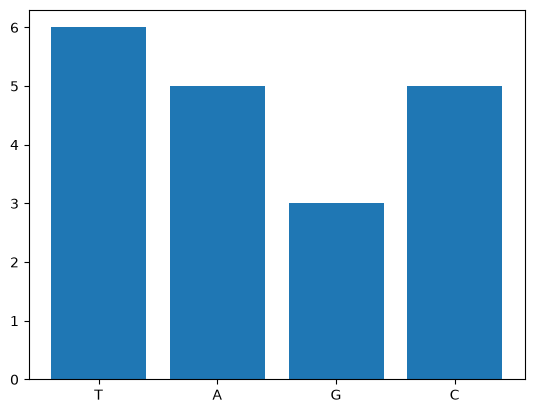

In [17]:
# bar(x, y)
plt.bar(counter_seq_1.keys(), counter_seq_1.values())